In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from train import train


In [2]:
# Data Preparation
def generate_sequences(n=128, variable_len=False, seed=13):
    """随机生成 n 组沿着正方形轮廓游走的坐标序列，每条序列随机选择起点、
    正向 / 反向绕行；可选固定长度或随机长度，叠加微小噪声；
    标签就是绕行方向，用来做序列分类训练。"""

    basic_corners = np.array([[-1, -1], [-1, 1], [1, 1], [1, -1]])
    # 创建独立随机数生成器
    rng = np.random.default_rng(seed)
    bases = rng.integers(4, size=n)
    if variable_len:
        # 3个可选值：0,1,2 → +2 → 2,3,4
        lengths = rng.integers(3, size=n) + 2
    else:
        lengths = [4] * n

    directions = rng.integers(2, size=n)

    points = [
        basic_corners[[(b + i) % 4 for i in range(4)]][slice(None, None, d * 2 - 1)][:l]
        + rng.standard_normal((l, 2)) * 0.1
        for b, d, l in zip(bases, directions, lengths)
    ]
    return np.array(points), np.array(directions)

In [3]:
# Training set
points, directions = generate_sequences(n=256, seed=13)
full_train = torch.as_tensor(points).float()
target_train = full_train[:, 2:]
train_data = TensorDataset(full_train, target_train)
generator = torch.Generator()
train_loader = DataLoader(train_data, batch_size=16, shuffle=True, generator=generator)
# Validation / Test Set
test_points, test_directions = generate_sequences(seed=19)
full_test = torch.as_tensor(test_points).float()
source_test = full_test[:, :2]
target_test = full_test[:, 2:]
test_data = TensorDataset(source_test, target_test)
test_loader = DataLoader(test_data, batch_size=16)

In [4]:
class PositionalEncoding(nn.Module):
    def __init__(self, max_len, d_model):
        super().__init__()
        self.d_model = d_model
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).float().unsqueeze(1)
        angular_speed = torch.exp(
            torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model)
        )
        # even dimensions
        pe[:, 0::2] = torch.sin(position * angular_speed)
        # odd dimensions
        pe[:, 1::2] = torch.cos(position * angular_speed)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        # x is N, L, D
        # pe is 1, maxlen, D
        scaled_x = x * np.sqrt(self.d_model)
        encoded = scaled_x + self.pe[:, : x.size(1), :]  # type: ignore
        return encoded


In [5]:
class TransformerModel(nn.Module):
    def __init__(self, input_len, target_len, n_features):
        super().__init__()
        self.transf = nn.Transformer(
            d_model=16,
            nhead=4,
            num_encoder_layers=2,
            num_decoder_layers=2,
            dim_feedforward=64,
            dropout=0.2,
            batch_first=True,
        )

        self.input_len = input_len
        self.target_len = target_len
        self.n_features = n_features
        # generate_square_subsequent_mask() that generates the appropriate mask
        # given the size (length) of the sequence.
        self.trg_masks = self.transf.generate_square_subsequent_mask(self.target_len)
        self.proj = nn.Linear(self.n_features, self.transf.d_model)
        self.linear = nn.Linear(self.transf.d_model, self.n_features)
        max_len = max(self.input_len, self.target_len)
        self.pe = PositionalEncoding(max_len, self.transf.d_model)
        self.norm = nn.LayerNorm(self.transf.d_model)

    def preprocess(self, seq):
        # seq is N, L, F
        # proj is N, L, d_model
        # pe is 1, L, d_model
        # output is N, L, d_model
        seq_proj = self.proj(seq)
        seq_enc = self.pe(seq_proj)
        # return seq_enc
        return self.norm(seq_enc)

    def encode_decode(self, source, target, source_mask=None, target_mask=None):
        src = self.preprocess(source)
        tgt = self.preprocess(target)

        out = self.transf(
            src, tgt, src_key_padding_mask=source_mask, tgt_mask=target_mask
        )
        out = self.linear(out)
        return out

    def predict(self, source_seq, source_mask=None):
        inputs = source_seq[:, -1:]
        for i in range(self.target_len):
            out = self.encode_decode(
                source_seq,
                inputs,
                source_mask=source_mask,
                target_mask=self.trg_masks[: i + 1, : i + 1],
            )
            out = torch.cat([inputs, out[:, -1:, :]], dim=-2)
            inputs = out.detach()

        outputs = out[:, 1:, :]  # type: ignore
        return outputs

    def forward(self, X, source_mask=None):
        self.trg_masks = self.trg_masks.type_as(X)
        source_seq = X[:, : self.input_len, :]

        if self.training:
            shifted_target_seq = X[:, self.input_len - 1 : -1, :]
            outputs = self.encode_decode(
                source_seq,
                shifted_target_seq,
                source_mask=source_mask,
                target_mask=self.trg_masks,
            )
        else:
            outputs = self.predict(source_seq, source_mask)

        return outputs


In [6]:
# Training set
points, directions = generate_sequences(n=256, seed=13)
full_train = torch.as_tensor(points).float()
target_train = full_train[:, 2:]
train_data = TensorDataset(full_train, target_train)
generator = torch.Generator()
train_loader = DataLoader(train_data, batch_size=16, shuffle=True, generator=generator)
# Test set
test_points, test_directions = generate_sequences(seed=19)
full_test = torch.as_tensor(test_points).float()
source_test = full_test[:, :2]
target_test = full_test[:, 2:]
test_data = TensorDataset(source_test, target_test)
test_loader = DataLoader(test_data, batch_size=16)

# Model

model_transformer = TransformerModel(input_len=2, target_len=2, n_features=2)
loss = nn.MSELoss()
optimizer = optim.Adam(model_transformer.parameters(), lr=3e-4)

# weights initialization
for p in model_transformer.parameters():
    # if p.dim() > 1:
    #     nn.init.xavier_uniform_(p)
    if p.dim() > 1:
        nn.init.kaiming_uniform_(p, nonlinearity="relu")
epoches = 1000

In [7]:
# Training
train_losses, test_losses = train(
    model_transformer, train_loader, test_loader, loss, optimizer, epoches
)

Epoch 1/1000 - loss: 3.0059 - val_loss: 2.0144
Epoch 2/1000 - loss: 2.2093 - val_loss: 1.0373
Epoch 3/1000 - loss: 2.0660 - val_loss: 0.7561
Epoch 4/1000 - loss: 1.7830 - val_loss: 0.6832
Epoch 5/1000 - loss: 1.7014 - val_loss: 0.6663
Epoch 6/1000 - loss: 1.5417 - val_loss: 0.6538
Epoch 7/1000 - loss: 1.4217 - val_loss: 0.6579
Epoch 8/1000 - loss: 1.3904 - val_loss: 0.6366
Epoch 9/1000 - loss: 1.3015 - val_loss: 0.6273
Epoch 10/1000 - loss: 1.3223 - val_loss: 0.6272
Epoch 11/1000 - loss: 1.2116 - val_loss: 0.6173
Epoch 12/1000 - loss: 1.1994 - val_loss: 0.6111
Epoch 13/1000 - loss: 1.1495 - val_loss: 0.6053
Epoch 14/1000 - loss: 1.1988 - val_loss: 0.6048
Epoch 15/1000 - loss: 1.0356 - val_loss: 0.5961
Epoch 16/1000 - loss: 1.0944 - val_loss: 0.5821
Epoch 17/1000 - loss: 1.0962 - val_loss: 0.5769
Epoch 18/1000 - loss: 1.1098 - val_loss: 0.5732
Epoch 19/1000 - loss: 0.9818 - val_loss: 0.5681
Epoch 20/1000 - loss: 1.0776 - val_loss: 0.5624
Epoch 21/1000 - loss: 0.9524 - val_loss: 0.5569
E

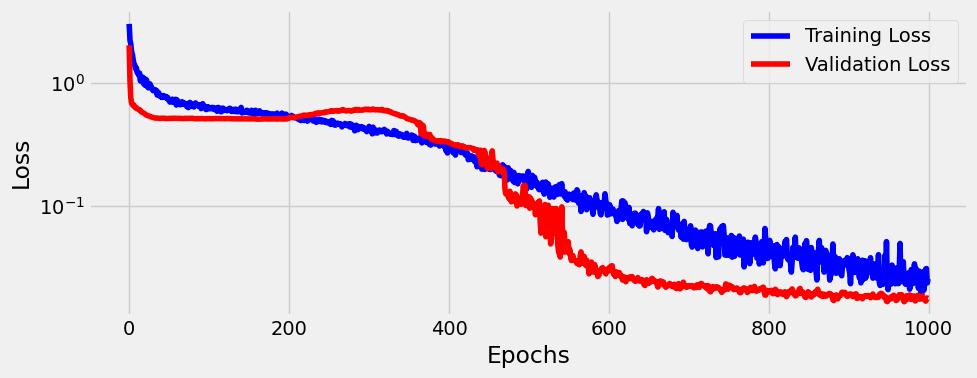

In [8]:
plt.style.use("fivethirtyeight")


def plot_losses():
    fig = plt.figure(figsize=(10, 4))
    plt.plot(train_losses, label="Training Loss", c="b")
    plt.plot(test_losses, label="Validation Loss", c="r")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    return fig


fig = plot_losses()


In [9]:
def sequence_pred(model, X, directions=None, n_rows=2, n_cols=5):
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axs = axs.flatten()

    for e, ax in enumerate(axs):
        first_corners = X[e, :2, :]
        model.eval()
        next_corners = (
            model(X[e : e + 1, :2].to(X.device)).squeeze().detach().cpu().numpy()
        )
        pred_corners = np.concatenate([first_corners, next_corners], axis=0)

        for j, corners in enumerate([X[e], pred_corners]):
            for i in range(4):
                coords = corners[i]
                color = "k"
                ax.scatter(*coords, c=color, s=400)
                if i == 3:
                    start = -1
                else:
                    start = i
                if (not j) or (j and i):
                    ax.plot(
                        *corners[[start, start + 1]].T,
                        c="k",
                        lw=2,
                        alpha=0.5,
                        linestyle="--" if j else "-",
                    )
                ax.text(
                    *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12
                )
                if directions is not None:
                    ax.set_title(f"{'Counter-' if not directions[e] else ''}Clockwise")

        ax.set_xlabel(r"$x_0$")
        ax.set_ylabel(r"$x_1$", rotation=0)
        ax.set_xlim([-1.45, 1.45])
        ax.set_ylim([-1.45, 1.45])

    fig.tight_layout()
    return fig


C:\Users\cuish\AppData\Local\Temp\ipykernel_7164\1587516764.py:31: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  *(coords - np.array([0.04, 0.04])), str(i + 1), c="w", fontsize=12


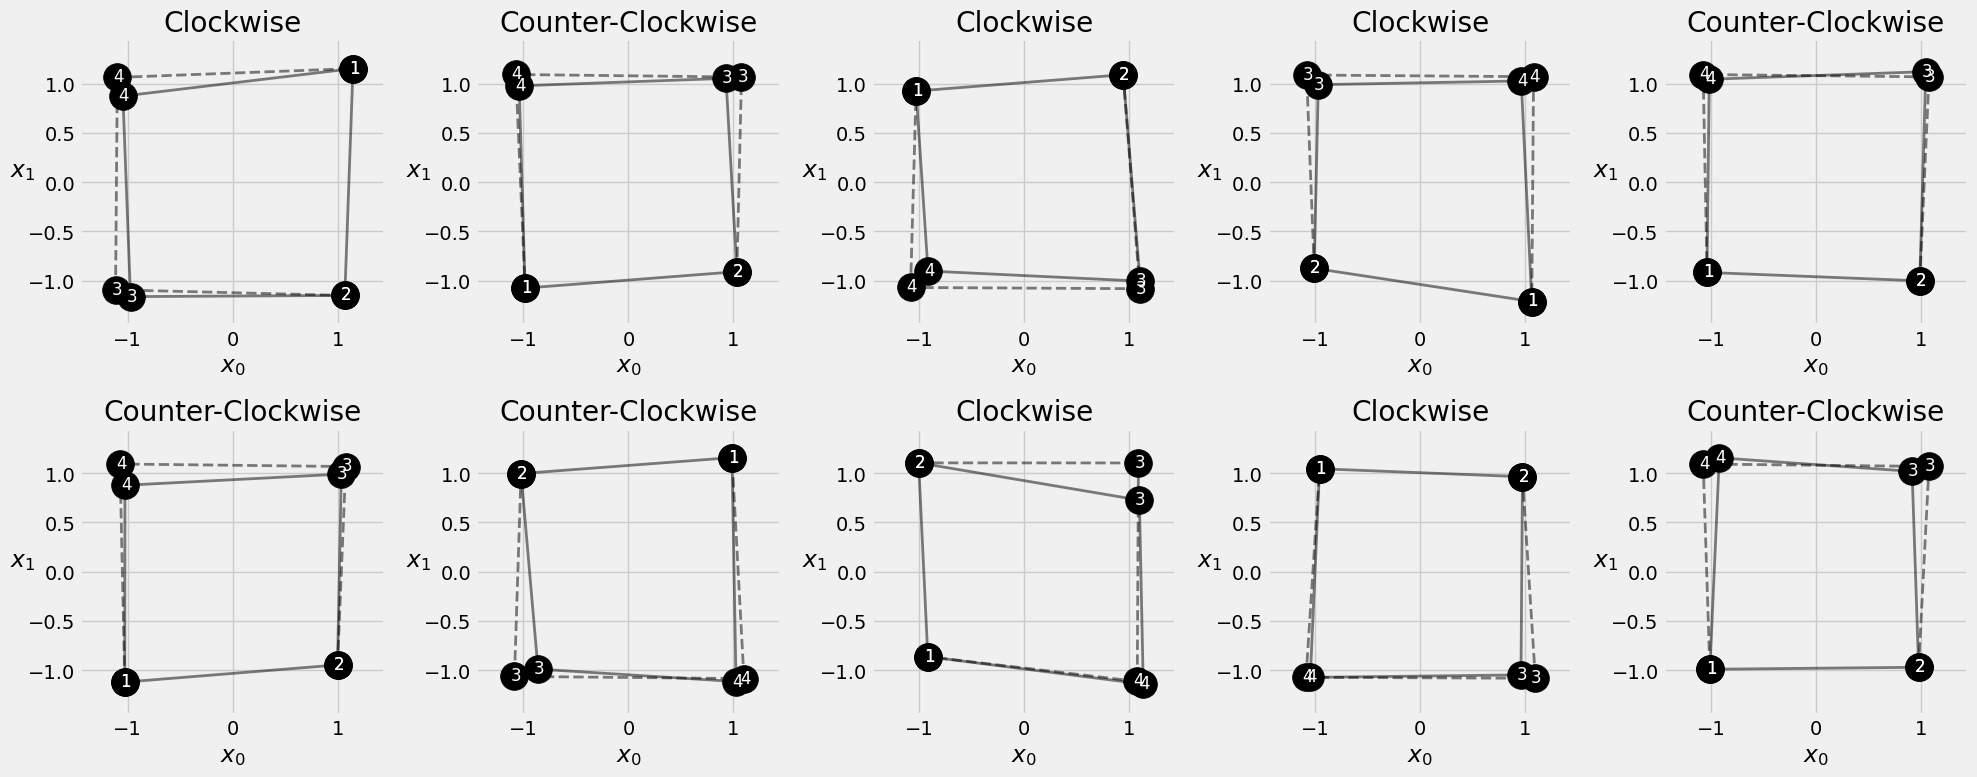

In [10]:
fig = sequence_pred(model_transformer, full_test, directions=test_directions)